In [2]:

!pip install -q pandas numpy matplotlib seaborn requests


In [3]:

import os
import json
import time
import getpass
import requests

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from datetime import datetime

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 11

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:

regions = {
    "Mansoura": {
        "latitude": 31.04,
        "longitude": 31.38
    },
    "Fayoum": {
        "latitude": 29.31,
        "longitude": 30.84
    },
    "Ismailia": {
        "latitude": 30.60,
        "longitude": 32.27
    },
    "Luxor": {
        "latitude": 25.69,
        "longitude": 32.64
    },
    "Marsa Matrouh": {
        "latitude": 31.35,
        "longitude": 27.24
    }
}

regions_df = pd.DataFrame(regions).T
regions_df


,latitude,longitude
Mansoura,31.04,31.38
Fayoum,29.31,30.84
Ismailia,30.60,32.27
Luxor,25.69,32.64
Marsa Matrouh,31.35,27.24


In [5]:

START_DATE = "01-01-2020"
END_DATE = "12-31-2025"

PRODUCT = "MOD13Q1.061"

print("Product:", PRODUCT)
print("Period:", START_DATE, "to", END_DATE)


Product: MOD13Q1.061
Period: 01-01-2020 to 12-31-2025


In [6]:

USERNAME = input("Enter your NASA Earthdata username: ")
PASSWORD = getpass.getpass("Enter your NASA Earthdata password: ")

BASE_URL = "https://appeears.earthdatacloud.nasa.gov/api"

login_response = requests.post(
    f"{BASE_URL}/login",
    auth=(USERNAME, PASSWORD),
    timeout=60
)

print("Status code:", login_response.status_code)

login_response.raise_for_status()

token = login_response.json()["token"]

headers = {
    "Authorization": f"Bearer {token}"
}

print("Successfully authenticated with AppEEARS!")


Enter your NASA Earthdata username:  manarsabry
Enter your NASA Earthdata password:  ········


Status code: 200
Successfully authenticated with AppEEARS!


In [7]:

products_response = requests.get(
    f"{BASE_URL}/product",
    headers=headers,
    timeout=60
)

products_response.raise_for_status()

products = products_response.json()

product_info = [
    p for p in products
    if p["ProductAndVersion"] == PRODUCT
]

print("Matching products:", len(product_info))

display(pd.DataFrame(product_info))


Matching products: 1


,Product,Platform,Description,RasterType,Resolution,TemporalGranularity,Version,Available,DocLink,Source,TemporalExtentStart,TemporalExtentEnd,Deleted,DOI,Info,ProductAndVersion
0,MOD13Q1,Terra MODIS,Vegetation Indices (NDVI & EVI),Tile,250m,16 day,061,True,https://doi.org/10.5067/MODIS/MOD13Q1.061,LP DAAC,2000-02-18,Present,False,10.5067/MODIS/MOD13Q1.061,{'collection_concept_id': 'C1748066515-LPCLOUD...,MOD13Q1.061


In [8]:

print("Product information:")
print(json.dumps(product_info[0], indent=4))

Product information:
{
    "Product": "MOD13Q1",
    "Platform": "Terra MODIS",
    "Description": "Vegetation Indices (NDVI & EVI)",
    "RasterType": "Tile",
    "Resolution": "250m",
    "TemporalGranularity": "16 day",
    "Version": "061",
    "Available": true,
    "DocLink": "https://doi.org/10.5067/MODIS/MOD13Q1.061",
    "Source": "LP DAAC",
    "TemporalExtentStart": "2000-02-18",
    "TemporalExtentEnd": "Present",
    "Deleted": false,
    "DOI": "10.5067/MODIS/MOD13Q1.061",
    "Info": {
        "collection_concept_id": "C1748066515-LPCLOUD",
        "provider_id": "lp_prod"
    },
    "ProductAndVersion": "MOD13Q1.061"
}


In [9]:

# Get the layers of MOD13Q1.061

layers_response = requests.get(
    f"{BASE_URL}/product/{PRODUCT}",
    headers=headers,
    timeout=60
)

layers_response.raise_for_status()

product_layers = layers_response.json()

print("Available Layers:")
print(json.dumps(product_layers, indent=4))


Available Layers:
{
    "_250m_16_days_EVI": {
        "AddOffset": 0.0,
        "Available": true,
        "DataType": "float32",
        "Description": "16 day EVI average",
        "Dimensions": [
            "time",
            "YDim",
            "XDim"
        ],
        "FillValue": -3000,
        "FillValueAll": [
            -3000
        ],
        "Group": "",
        "Info": {},
        "IsQA": false,
        "Layer": "_250m_16_days_EVI",
        "OrigDataType": "int16",
        "OrigValidMax": 10000,
        "OrigValidMin": -2000,
        "QualityLayers": "['_250m_16_days_VI_Quality']",
        "QualityProductAndVersion": "MOD13Q1.061",
        "ScaleFactor": 0.0001,
        "Units": "EVI",
        "ValidMax": 1.0,
        "ValidMin": -0.200000003,
        "XSize": 4800,
        "YSize": 4800
    },
    "_250m_16_days_MIR_reflectance": {
        "AddOffset": 0.0,
        "Available": true,
        "DataType": "float32",
        "Description": "250m 16 days MIR reflectance"

In [10]:

layers_df = pd.DataFrame([
    {
        "Layer": layer_name,
        **layer_info
    }
    for layer_name, layer_info in product_layers.items()
])

display(layers_df)


,Layer,AddOffset,Available,DataType,Description,Dimensions,FillValue,FillValueAll,Group,Info,...,OrigValidMax,OrigValidMin,QualityLayers,QualityProductAndVersion,ScaleFactor,Units,ValidMax,ValidMin,XSize,YSize
0,_250m_16_days_EVI,0.0,True,float32,16 day EVI average,"[time, YDim, XDim]",-3000,[-3000],,{},...,10000,-2000,['_250m_16_days_VI_Quality'],MOD13Q1.061,0.0001,EVI,1.0,-0.2,4800,4800
1,_250m_16_days_MIR_reflectance,0.0,True,float32,250m 16 days MIR reflectance,"[time, YDim, XDim]",-1000,[-1000],,{},...,10000,0,['_250m_16_days_pixel_reliability'],MOD13Q1.061,0.0001,,1.0,0.0,4800,4800
2,_250m_16_days_NDVI,0.0,True,float32,16 day NDVI average,"[time, YDim, XDim]",-3000,[-3000],,{},...,10000,-2000,['_250m_16_days_VI_Quality'],MOD13Q1.061,0.0001,NDVI,1.0,-0.2,4800,4800
3,_250m_16_days_NIR_reflectance,0.0,True,float32,250m 16 days NIR reflectance,"[time, YDim, XDim]",-1000,[-1000],,{},...,10000,0,['_250m_16_days_pixel_reliability'],MOD13Q1.061,0.0001,,1.0,0.0,4800,4800
4,_250m_16_days_VI_Quality,,True,uint16,250m 16 days VI Quality,"[time, YDim, XDim]",65535,[65535],,{},...,65534,0,,,,,65534.0,0.0,4800,4800
5,_250m_16_days_blue_reflectance,0.0,True,float32,250m 16 days blue reflectance,"[time, YDim, XDim]",-1000,[-1000],,{},...,10000,0,['_250m_16_days_pixel_reliability'],MOD13Q1.061,0.0001,,1.0,0.0,4800,4800
6,_250m_16_days_composite_day_of_the_year,,True,int16,250m 16 days composite day of the year,"[time, YDim, XDim]",-1,[-1],,{},...,366,1,,,,,366.0,1.0,4800,4800
7,_250m_16_days_pixel_reliability,,True,int32,250m 16 days pixel reliability,"[time, YDim, XDim]",-1,[-1],,{},...,3,0,,,,,3.0,0.0,4800,4800
8,_250m_16_days_red_reflectance,0.0,True,float32,250m 16 days red reflectance,"[time, YDim, XDim]",-1000,[-1000],,{},...,10000,0,['_250m_16_days_pixel_reliability'],MOD13Q1.061,0.0001,,1.0,0.0,4800,4800
9,_250m_16_days_relative_azimuth_angle,0.0,True,float32,250m 16 days relative azimuth angle,"[time, YDim, XDim]",-4000,[-4000],,{},...,18000,-18000,,,0.01,,180.0,-180.0,4800,4800


In [11]:
# Select the required MODIS layers

selected_layers = [
    "_250m_16_days_NDVI",
    "_250m_16_days_EVI",
    "_250m_16_days_VI_Quality",
    "_250m_16_days_pixel_reliability"
]

# Check that all selected layers exist
for layer in selected_layers:
    if layer in product_layers:
        print(f"Available: {layer}")
    else:
        print(f"Missing: {layer}")

Available: _250m_16_days_NDVI
Available: _250m_16_days_EVI
Available: _250m_16_days_VI_Quality
Available: _250m_16_days_pixel_reliability


In [12]:
coordinates = [
    {
        "id": name.replace(" ", "_"),
        "latitude": info["latitude"],
        "longitude": info["longitude"],
        "category": name
    }
    for name, info in regions.items()
]

print(json.dumps(coordinates, indent=4))

[
    {
        "id": "Mansoura",
        "latitude": 31.04,
        "longitude": 31.38,
        "category": "Mansoura"
    },
    {
        "id": "Fayoum",
        "latitude": 29.31,
        "longitude": 30.84,
        "category": "Fayoum"
    },
    {
        "id": "Ismailia",
        "latitude": 30.6,
        "longitude": 32.27,
        "category": "Ismailia"
    },
    {
        "id": "Luxor",
        "latitude": 25.69,
        "longitude": 32.64,
        "category": "Luxor"
    },
    {
        "id": "Marsa_Matrouh",
        "latitude": 31.35,
        "longitude": 27.24,
        "category": "Marsa Matrouh"
    }
]


In [13]:
task_payload = {
    "task_name": "SpaceSoil_MODIS_Vegetation_2020_2025",
    "task_type": "point",
    "params": {
        "dates": [
            {
                "startDate": START_DATE,
                "endDate": END_DATE
            }
        ],
        "layers": [
            {
                "product": PRODUCT,
                "layer": layer
            }
            for layer in selected_layers
        ],
        "coordinates": coordinates
    }
}

print(json.dumps(task_payload, indent=4))

{
    "task_name": "SpaceSoil_MODIS_Vegetation_2020_2025",
    "task_type": "point",
    "params": {
        "dates": [
            {
                "startDate": "01-01-2020",
                "endDate": "12-31-2025"
            }
        ],
        "layers": [
            {
                "product": "MOD13Q1.061",
                "layer": "_250m_16_days_NDVI"
            },
            {
                "product": "MOD13Q1.061",
                "layer": "_250m_16_days_EVI"
            },
            {
                "product": "MOD13Q1.061",
                "layer": "_250m_16_days_VI_Quality"
            },
            {
                "product": "MOD13Q1.061",
                "layer": "_250m_16_days_pixel_reliability"
            }
        ],
        "coordinates": [
            {
                "id": "Mansoura",
                "latitude": 31.04,
                "longitude": 31.38,
                "category": "Mansoura"
            },
            {
                "id": "Fayoum"

In [14]:
task_response = requests.post(
    f"{BASE_URL}/task",
    headers=headers,
    json=task_payload,
    timeout=120
)

print("Status Code:", task_response.status_code)

print(json.dumps(
    task_response.json(),
    indent=4
))

task_response.raise_for_status()

task_id = task_response.json()["task_id"]

print("\nTask ID:", task_id)

Status Code: 202
{
    "task_id": "4a1829b0-9507-46ee-ae1f-42ad322108d8",
    "status": "pending"
}

Task ID: 4a1829b0-9507-46ee-ae1f-42ad322108d8


In [15]:
status_response = requests.get(
    f"{BASE_URL}/task/{task_id}",
    headers=headers,
    timeout=60
)

print("Status Code:", status_response.status_code)
status_response.raise_for_status()

task_status = status_response.json()

print("Task Status:", task_status.get("status"))
print(json.dumps(task_status, indent=4))

Status Code: 200
Task Status: pending
{
    "tier": 1,
    "params": {
        "dates": [
            {
                "endDate": "12-31-2025",
                "startDate": "01-01-2020"
            }
        ],
        "layers": [
            {
                "layer": "_250m_16_days_NDVI",
                "product": "MOD13Q1.061"
            },
            {
                "layer": "_250m_16_days_EVI",
                "product": "MOD13Q1.061"
            },
            {
                "layer": "_250m_16_days_VI_Quality",
                "product": "MOD13Q1.061"
            },
            {
                "layer": "_250m_16_days_pixel_reliability",
                "product": "MOD13Q1.061"
            }
        ],
        "coordinates": [
            {
                "id": "Mansoura",
                "category": "Mansoura",
                "latitude": 31.04,
                "longitude": 31.38
            },
            {
                "id": "Fayoum",
                "category": 

In [17]:
import time

while True:

    response = requests.get(
        f"{BASE_URL}/task/{task_id}",
        headers=headers,
        timeout=60
    )

    response.raise_for_status()

    status = response.json()["status"]

    print("Current Status:", status)

    if status == "done":
        print("Data processing completed!")
        break

    elif status == "error":
        print("Task failed!")
        print(response.json())
        break

    time.sleep(30)

Current Status: pending
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Current Status: processing
Curr

In [18]:
files_response = requests.get(
    f"{BASE_URL}/bundle/{task_id}",
    headers=headers,
    timeout=60
)

print("Status Code:", files_response.status_code)

files_response.raise_for_status()

bundle_data = files_response.json()

print(json.dumps(bundle_data, indent=4))

Status Code: 200
{
    "files": [
        {
            "sha256": "bb99285966c6552d37bd90861e66702fee85604c12e2280a4e651a99bcc3d933",
            "file_id": "56aa9333-697d-422a-aa5e-e267d0269c00",
            "file_name": "SpaceSoil-MODIS-Vegetation-2020-2025-MOD13Q1-061-results.csv",
            "file_size": 251934,
            "file_type": "csv",
            "s3_url": "s3://appeears-output/4a1829b0-9507-46ee-ae1f-42ad322108d8/SpaceSoil-MODIS-Vegetation-2020-2025-MOD13Q1-061-results.csv"
        },
        {
            "sha256": "f7b98e57f72091e1a7bb54eaf8e5fcb2056ffc52079153ceeab1cf180781e213",
            "file_id": "0ee3270c-91a2-408c-a17b-6f5500dc7078",
            "file_name": "SpaceSoil-MODIS-Vegetation-2020-2025-granule-list.txt",
            "file_size": 45036,
            "file_type": "txt",
            "s3_url": "s3://appeears-output/4a1829b0-9507-46ee-ae1f-42ad322108d8/SpaceSoil-MODIS-Vegetation-2020-2025-granule-list.txt"
        },
        {
            "sha256": "be655f

In [19]:
files_df = pd.DataFrame(bundle_data["files"])

display(files_df)

,sha256,file_id,file_name,file_size,file_type,s3_url
0,bb99285966c6552d37bd90861e66702fee85604c12e228...,56aa9333-697d-422a-aa5e-e267d0269c00,SpaceSoil-MODIS-Vegetation-2020-2025-MOD13Q1-0...,251934,csv,s3://appeears-output/4a1829b0-9507-46ee-ae1f-4...
1,f7b98e57f72091e1a7bb54eaf8e5fcb2056ffc52079153...,0ee3270c-91a2-408c-a17b-6f5500dc7078,SpaceSoil-MODIS-Vegetation-2020-2025-granule-l...,45036,txt,s3://appeears-output/4a1829b0-9507-46ee-ae1f-4...
2,be655fb1b39d02e1cdb561414b765c10829100c44319ba...,a0e49b84-b48a-46d5-81d5-835af0683321,SpaceSoil-MODIS-Vegetation-2020-2025-request.json,1369,json,s3://appeears-output/4a1829b0-9507-46ee-ae1f-4...
3,fc5da331e4ef81f440322b1b19da66653641f3dcff23d7...,80f556f9-409f-49f9-b973-2df3f242fe96,SpaceSoil-MODIS-Vegetation-2020-2025-MOD13Q1-0...,18254,xml,s3://appeears-output/4a1829b0-9507-46ee-ae1f-4...
4,b828734d56e38631dfbb490e3cc17c66c7be2e09582b6e...,da0ca470-12a5-4565-99b3-4586352212d0,README.md,30541,txt,s3://appeears-output/4a1829b0-9507-46ee-ae1f-4...


In [20]:
import os

os.makedirs("SpaceSoil_Data/MODIS", exist_ok=True)

csv_file = files_df.loc[
    files_df["file_type"] == "csv"
].iloc[0]

download_url = (
    f"{BASE_URL}/bundle/{task_id}/{csv_file['file_id']}"
)

download_response = requests.get(
    download_url,
    headers=headers,
    timeout=180
)

print("Status:", download_response.status_code)

download_response.raise_for_status()

csv_path = os.path.join(
    "SpaceSoil_Data/MODIS",
    csv_file["file_name"]
)

with open(csv_path, "wb") as f:
    f.write(download_response.content)

print("Downloaded:", csv_path)
print("File size:", os.path.getsize(csv_path), "bytes")

Status: 200
Downloaded: SpaceSoil_Data/MODIS/SpaceSoil-MODIS-Vegetation-2020-2025-MOD13Q1-061-results.csv
File size: 251934 bytes


In [21]:
modis_raw = pd.read_csv(csv_path)

print("Dataset Shape:", modis_raw.shape)

print("\nColumns:")
print(modis_raw.columns.tolist())

display(modis_raw.head(10))

Dataset Shape: (695, 34)

Columns:
['Category', 'ID', 'Latitude', 'Longitude', 'Date', 'MODIS_Tile', 'MOD13Q1_061_Line_Y_250m', 'MOD13Q1_061_Sample_X_250m', 'MOD13Q1_061__250m_16_days_EVI', 'MOD13Q1_061__250m_16_days_NDVI', 'MOD13Q1_061__250m_16_days_VI_Quality', 'MOD13Q1_061__250m_16_days_pixel_reliability', 'MOD13Q1_061__250m_16_days_VI_Quality_bitmask', 'MOD13Q1_061__250m_16_days_VI_Quality_MODLAND', 'MOD13Q1_061__250m_16_days_VI_Quality_MODLAND_Description', 'MOD13Q1_061__250m_16_days_VI_Quality_VI_Usefulness', 'MOD13Q1_061__250m_16_days_VI_Quality_VI_Usefulness_Description', 'MOD13Q1_061__250m_16_days_VI_Quality_Aerosol_Quantity', 'MOD13Q1_061__250m_16_days_VI_Quality_Aerosol_Quantity_Description', 'MOD13Q1_061__250m_16_days_VI_Quality_Adjacent_cloud_detected', 'MOD13Q1_061__250m_16_days_VI_Quality_Adjacent_cloud_detected_Description', 'MOD13Q1_061__250m_16_days_VI_Quality_Atmosphere_BRDF_Correction', 'MOD13Q1_061__250m_16_days_VI_Quality_Atmosphere_BRDF_Correction_Description', '

,Category,ID,Latitude,Longitude,Date,MODIS_Tile,MOD13Q1_061_Line_Y_250m,MOD13Q1_061_Sample_X_250m,MOD13Q1_061__250m_16_days_EVI,MOD13Q1_061__250m_16_days_NDVI,...,MOD13Q1_061__250m_16_days_VI_Quality_Mixed_Clouds_Description,MOD13Q1_061__250m_16_days_VI_Quality_Land/Water_Mask,MOD13Q1_061__250m_16_days_VI_Quality_Land/Water_Mask_Description,MOD13Q1_061__250m_16_days_VI_Quality_Possible_snow/ice,MOD13Q1_061__250m_16_days_VI_Quality_Possible_snow/ice_Description,MOD13Q1_061__250m_16_days_VI_Quality_Possible_shadow,MOD13Q1_061__250m_16_days_VI_Quality_Possible_shadow_Description,MOD13Q1_061__250m_16_days_pixel_reliability_bitmask,MOD13Q1_061__250m_16_days_pixel_reliability_MODLAND,MOD13Q1_061__250m_16_days_pixel_reliability_MODLAND_Description
0,Fayoum,Fayoum,29.31,30.84,2019-12-19,h20v06,331.0,3308.0,0.0628,0.1362,...,No,0b001,Land (Nothing else but land),0b0,No,0b0,No,0b00000000000000000000000000000011,0b00000000000000000000000000000011,"Cloudy data, Target not visible, covered with ..."
1,Fayoum,Fayoum,29.31,30.84,2020-01-01,h20v06,331.0,3308.0,0.0921,0.1921,...,No,0b001,Land (Nothing else but land),0b0,No,0b0,No,0b00000000000000000000000000000001,0b00000000000000000000000000000001,"Marginal data, Useful, but look at other QA in..."
2,Fayoum,Fayoum,29.31,30.84,2020-01-17,h20v06,331.0,3308.0,0.0601,0.1380,...,No,0b001,Land (Nothing else but land),0b0,No,0b0,No,0b00000000000000000000000000000011,0b00000000000000000000000000000011,"Cloudy data, Target not visible, covered with ..."
3,Fayoum,Fayoum,29.31,30.84,2020-02-02,h20v06,331.0,3308.0,0.0697,0.1270,...,Yes,0b001,Land (Nothing else but land),0b0,No,0b0,No,0b00000000000000000000000000000011,0b00000000000000000000000000000011,"Cloudy data, Target not visible, covered with ..."
4,Fayoum,Fayoum,29.31,30.84,2020-02-18,h20v06,331.0,3308.0,0.0893,0.1330,...,Yes,0b001,Land (Nothing else but land),0b0,No,0b0,No,0b00000000000000000000000000000011,0b00000000000000000000000000000011,"Cloudy data, Target not visible, covered with ..."
5,Fayoum,Fayoum,29.31,30.84,2020-03-05,h20v06,331.0,3308.0,0.0812,0.1351,...,No,0b001,Land (Nothing else but land),0b0,No,0b0,No,0b00000000000000000000000000000000,0b00000000000000000000000000000000,"Good data, use with confidence"
6,Fayoum,Fayoum,29.31,30.84,2020-03-21,h20v06,331.0,3308.0,0.0971,0.1387,...,No,0b001,Land (Nothing else but land),0b0,No,0b0,No,0b00000000000000000000000000000000,0b00000000000000000000000000000000,"Good data, use with confidence"
7,Fayoum,Fayoum,29.31,30.84,2020-04-06,h20v06,331.0,3308.0,0.0892,0.1378,...,No,0b001,Land (Nothing else but land),0b0,No,0b0,No,0b00000000000000000000000000000000,0b00000000000000000000000000000000,"Good data, use with confidence"
8,Fayoum,Fayoum,29.31,30.84,2020-04-22,h20v06,331.0,3308.0,0.0917,0.1406,...,No,0b001,Land (Nothing else but land),0b0,No,0b0,No,0b00000000000000000000000000000000,0b00000000000000000000000000000000,"Good data, use with confidence"
9,Fayoum,Fayoum,29.31,30.84,2020-05-08,h20v06,331.0,3308.0,0.0917,0.1349,...,No,0b001,Land (Nothing else but land),0b0,No,0b0,No,0b00000000000000000000000000000000,0b00000000000000000000000000000000,"Good data, use with confidence"


In [22]:
print("Dataset Information:")
modis_raw.info()

print("\nStatistical Summary:")
display(modis_raw.describe(include="all").T)

print("\nMissing Values:")
display(
    modis_raw.isnull().sum().to_frame("Missing Values")
)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 695 entries, 0 to 694
Data columns (total 34 columns):
 #   Column                                                                       Non-Null Count  Dtype  
---  ------                                                                       --------------  -----  
 0   Category                                                                     695 non-null    object 
 1   ID                                                                           695 non-null    object 
 2   Latitude                                                                     695 non-null    float64
 3   Longitude                                                                    695 non-null    float64
 4   Date                                                                         695 non-null    object 
 5   MODIS_Tile                                                                   695 non-null    object 
 6   MOD13Q1_061_Line_Y_25

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Category,695,5,Fayoum,139,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ID,695,5,Fayoum,139,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,695.0,NaN,NaN,NaN,29.598,2.075537,25.69,29.31,30.6,31.04,31.35
Longitude,695.0,NaN,NaN,NaN,30.874,1.926521,27.24,30.84,31.38,32.27,32.64
Date,695,139,2019-12-19,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MODIS_Tile,695,2,h20v05,417,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MOD13Q1_061_Line_Y_250m,695.0,NaN,NaN,NaN,3072.2,1629.917498,331.0,2068.0,4151.0,4300.0,4511.0
MOD13Q1_061_Sample_X_250m,695.0,NaN,NaN,NaN,3285.8,967.752296,1566.0,3305.0,3308.0,3732.0,4518.0
MOD13Q1_061__250m_16_days_EVI,695.0,NaN,NaN,NaN,0.080049,0.017268,0.0381,0.06675,0.0797,0.0917,0.147
MOD13Q1_061__250m_16_days_NDVI,695.0,NaN,NaN,NaN,0.128305,0.02308,0.0593,0.1141,0.1284,0.14125,0.3307



Missing Values:


,Missing Values
Category,0
ID,0
Latitude,0
Longitude,0
Date,0
MODIS_Tile,0
MOD13Q1_061_Line_Y_250m,0
MOD13Q1_061_Sample_X_250m,0
MOD13Q1_061__250m_16_days_EVI,0
MOD13Q1_061__250m_16_days_NDVI,0


In [23]:
print("Rows per Region:")

display(
    modis_raw.groupby("Category")
    .size()
    .to_frame("Number of Records")
)

Rows per Region:


,Number of Records
Category,
Fayoum,139
Ismailia,139
Luxor,139
Mansoura,139
Marsa Matrouh,139


In [24]:
# Rename long column names for easier access
reliability_col = "MOD13Q1_061__250m_16_days_pixel_reliability"
reliability_desc_col = "MOD13Q1_061__250m_16_days_pixel_reliability_MODLAND_Description"

# 1. Distribution of pixel reliability
print("Pixel Reliability Distribution:")
display(
    modis_raw[reliability_desc_col]
    .value_counts()
    .to_frame("Number of Records")
)

# 2. Reliability distribution per region
print("\nReliability per Region:")
display(
    modis_raw.pivot_table(
        index="Category",
        columns=reliability_desc_col,
        values="Date",
        aggfunc="count",
        fill_value=0
    )
)

# 3. Date range
modis_raw["Date"] = pd.to_datetime(modis_raw["Date"])

print("\nDate Range:")
print("First date:", modis_raw["Date"].min())
print("Last date:", modis_raw["Date"].max())

# 4. Check duplicate records
print("\nDuplicate Region-Date Records:")
print(
    modis_raw.duplicated(
        subset=["Category", "Date"]
    ).sum()
)

# 5. Check vegetation indices ranges
print("\nNDVI and EVI Ranges:")
display(
    modis_raw[
        [
            "MOD13Q1_061__250m_16_days_NDVI",
            "MOD13Q1_061__250m_16_days_EVI"
        ]
    ].describe().T
)

Pixel Reliability Distribution:


,Number of Records
MOD13Q1_061__250m_16_days_pixel_reliability_MODLAND_Description,
"Good data, use with confidence",491
"Marginal data, Useful, but look at other QA information",149
"Cloudy data, Target not visible, covered with cloud",55



Reliability per Region:


MOD13Q1_061__250m_16_days_pixel_reliability_MODLAND_Description,"Cloudy data, Target not visible, covered with cloud","Good data, use with confidence","Marginal data, Useful, but look at other QA information"
Category,,,
Fayoum,20,110,9
Ismailia,5,131,3
Luxor,12,127,0
Mansoura,3,121,15
Marsa Matrouh,15,2,122



Date Range:
First date: 2019-12-19 00:00:00
Last date: 2025-12-19 00:00:00

Duplicate Region-Date Records:
0

NDVI and EVI Ranges:


,count,mean,std,min,25%,50%,75%,max
MOD13Q1_061__250m_16_days_NDVI,695.0,0.128305,0.023080,0.0593,0.11410,0.1284,0.14125,0.3307
MOD13Q1_061__250m_16_days_EVI,695.0,0.080049,0.017268,0.0381,0.06675,0.0797,0.09170,0.1470


In [25]:
# Keep the original dataset unchanged
modis_cleaned = modis_raw.copy()

# Rename important columns
modis_cleaned = modis_cleaned.rename(columns={
    "Category": "Region",
    "MOD13Q1_061__250m_16_days_NDVI": "NDVI",
    "MOD13Q1_061__250m_16_days_EVI": "EVI",
    "MOD13Q1_061__250m_16_days_pixel_reliability": "Pixel_Reliability",
    "MOD13Q1_061__250m_16_days_pixel_reliability_MODLAND_Description": "Reliability_Description",
    "MOD13Q1_061__250m_16_days_VI_Quality": "VI_Quality"
})

# Convert date
modis_cleaned["Date"] = pd.to_datetime(
    modis_cleaned["Date"]
)

# Create quality flags
modis_cleaned["Is_Good"] = (
    modis_cleaned["Pixel_Reliability"] == 0
)

modis_cleaned["Is_Marginal"] = (
    modis_cleaned["Pixel_Reliability"] == 1
)

modis_cleaned["Is_Cloudy"] = (
    modis_cleaned["Pixel_Reliability"] == 3
)

# Add time features
modis_cleaned["Year"] = modis_cleaned["Date"].dt.year
modis_cleaned["Month"] = modis_cleaned["Date"].dt.month
modis_cleaned["Season"] = (
    modis_cleaned["Month"] % 12 // 3 + 1
)

# Check results
print("Cleaned Dataset Shape:", modis_cleaned.shape)

display(
    modis_cleaned[
        [
            "Region", "Date", "Year", "Month",
            "NDVI", "EVI", "Pixel_Reliability",
            "Is_Good", "Is_Marginal", "Is_Cloudy"
        ]
    ].head(10)
)

Cleaned Dataset Shape: (695, 40)


,Region,Date,Year,Month,NDVI,EVI,Pixel_Reliability,Is_Good,Is_Marginal,Is_Cloudy
0,Fayoum,2019-12-19,2019,12,0.1362,0.0628,3.0,False,False,True
1,Fayoum,2020-01-01,2020,1,0.1921,0.0921,1.0,False,True,False
2,Fayoum,2020-01-17,2020,1,0.1380,0.0601,3.0,False,False,True
3,Fayoum,2020-02-02,2020,2,0.1270,0.0697,3.0,False,False,True
4,Fayoum,2020-02-18,2020,2,0.1330,0.0893,3.0,False,False,True
5,Fayoum,2020-03-05,2020,3,0.1351,0.0812,0.0,True,False,False
6,Fayoum,2020-03-21,2020,3,0.1387,0.0971,0.0,True,False,False
7,Fayoum,2020-04-06,2020,4,0.1378,0.0892,0.0,True,False,False
8,Fayoum,2020-04-22,2020,4,0.1406,0.0917,0.0,True,False,False
9,Fayoum,2020-05-08,2020,5,0.1349,0.0917,0.0,True,False,False


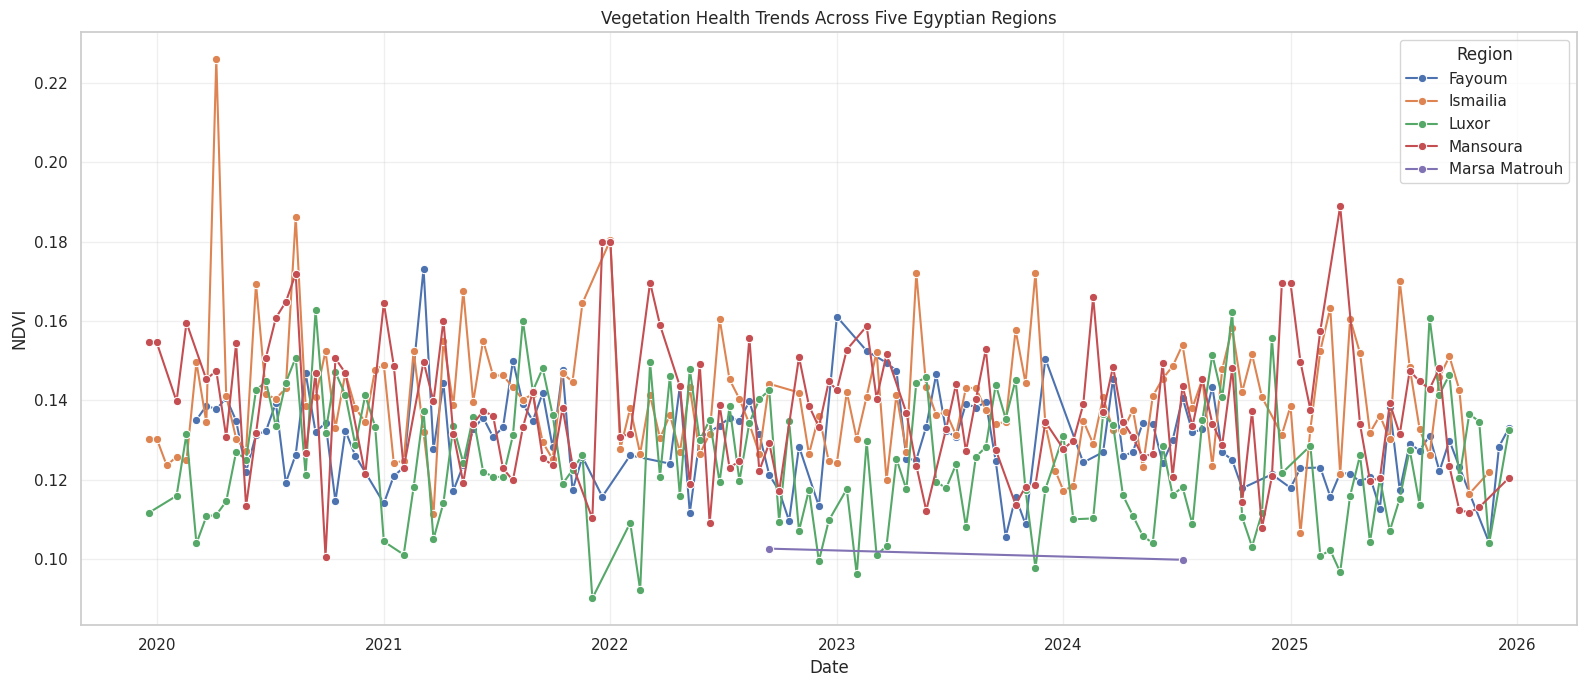

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

good_data = modis_cleaned[
    modis_cleaned["Is_Good"]
].copy()

plt.figure(figsize=(16, 7))

sns.lineplot(
    data=good_data,
    x="Date",
    y="NDVI",
    hue="Region",
    marker="o"
)

plt.title("Vegetation Health Trends Across Five Egyptian Regions")
plt.xlabel("Date")
plt.ylabel("NDVI")
plt.legend(title="Region")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Count data quality for each region
quality_summary = modis_cleaned.groupby("Region").agg(
    Total_Records=("NDVI", "count"),
    Good_Records=("Is_Good", "sum"),
    Marginal_Records=("Is_Marginal", "sum"),
    Cloudy_Records=("Is_Cloudy", "sum")
)

# Calculate percentages
quality_summary["Good_Percentage"] = (
    quality_summary["Good_Records"] / quality_summary["Total_Records"] * 100
).round(2)

display(quality_summary)

,Total_Records,Good_Records,Marginal_Records,Cloudy_Records,Good_Percentage
Region,,,,,
Fayoum,139,110,9,20,79.14
Ismailia,139,131,3,5,94.24
Luxor,139,127,0,12,91.37
Mansoura,139,121,15,3,87.05
Marsa Matrouh,139,2,122,15,1.44


In [31]:
for name, value in globals().copy().items():
    if isinstance(value, pd.DataFrame):
        print(name, value.shape)

_ (5, 2)
regions_df (5, 2)
_4 (5, 2)
layers_df (12, 22)
files_df (5, 6)
modis_raw (695, 34)
modis_cleaned (695, 40)
good_data (491, 40)
quality_summary (5, 5)


,Total_Records,Good,Marginal,Cloudy
Region,,,,
Fayoum,139,110,9,20
Ismailia,139,131,3,5
Luxor,139,127,0,12
Mansoura,139,121,15,3
Marsa Matrouh,139,2,122,15


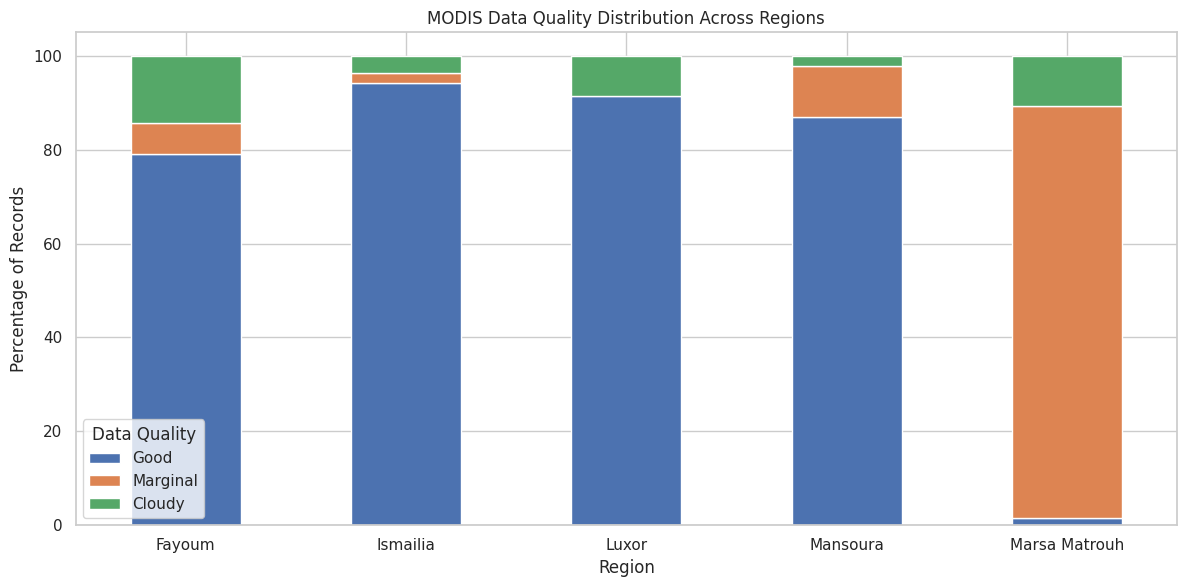

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

quality_summary = modis_cleaned.groupby("Region").agg(
    Total_Records=("Pixel_Reliability", "count"),
    Good=("Is_Good", "sum"),
    Marginal=("Is_Marginal", "sum"),
    Cloudy=("Is_Cloudy", "sum")
)

quality_percent = quality_summary[
    ["Good", "Marginal", "Cloudy"]
].div(quality_summary["Total_Records"], axis=0) * 100

display(quality_summary)
quality_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("MODIS Data Quality Distribution Across Regions")
plt.xlabel("Region")
plt.ylabel("Percentage of Records")
plt.xticks(rotation=0)
plt.legend(title="Data Quality")
plt.tight_layout()
plt.show()

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a working copy
modis_eda = modis_cleaned.copy()

# Convert Date to datetime
modis_eda["Date"] = pd.to_datetime(modis_eda["Date"])

# Sort by region and date
modis_eda = modis_eda.sort_values(
    by=["Region", "Date"]
).reset_index(drop=True)

print("Dataset Shape:", modis_eda.shape)
print("Date Range:", modis_eda["Date"].min(), "to", modis_eda["Date"].max())

display(modis_eda.head())

Dataset Shape: (695, 40)
Date Range: 2019-12-19 00:00:00 to 2025-12-19 00:00:00


,Region,ID,Latitude,Longitude,Date,MODIS_Tile,MOD13Q1_061_Line_Y_250m,MOD13Q1_061_Sample_X_250m,EVI,NDVI,...,MOD13Q1_061__250m_16_days_VI_Quality_Possible_shadow_Description,MOD13Q1_061__250m_16_days_pixel_reliability_bitmask,MOD13Q1_061__250m_16_days_pixel_reliability_MODLAND,Reliability_Description,Is_Good,Is_Marginal,Is_Cloudy,Year,Month,Season
0,Fayoum,Fayoum,29.31,30.84,2019-12-19,h20v06,331.0,3308.0,0.0628,0.1362,...,No,0b00000000000000000000000000000011,0b00000000000000000000000000000011,"Cloudy data, Target not visible, covered with ...",False,False,True,2019,12,1
1,Fayoum,Fayoum,29.31,30.84,2020-01-01,h20v06,331.0,3308.0,0.0921,0.1921,...,No,0b00000000000000000000000000000001,0b00000000000000000000000000000001,"Marginal data, Useful, but look at other QA in...",False,True,False,2020,1,1
2,Fayoum,Fayoum,29.31,30.84,2020-01-17,h20v06,331.0,3308.0,0.0601,0.1380,...,No,0b00000000000000000000000000000011,0b00000000000000000000000000000011,"Cloudy data, Target not visible, covered with ...",False,False,True,2020,1,1
3,Fayoum,Fayoum,29.31,30.84,2020-02-02,h20v06,331.0,3308.0,0.0697,0.1270,...,No,0b00000000000000000000000000000011,0b00000000000000000000000000000011,"Cloudy data, Target not visible, covered with ...",False,False,True,2020,2,1
4,Fayoum,Fayoum,29.31,30.84,2020-02-18,h20v06,331.0,3308.0,0.0893,0.1330,...,No,0b00000000000000000000000000000011,0b00000000000000000000000000000011,"Cloudy data, Target not visible, covered with ...",False,False,True,2020,2,1


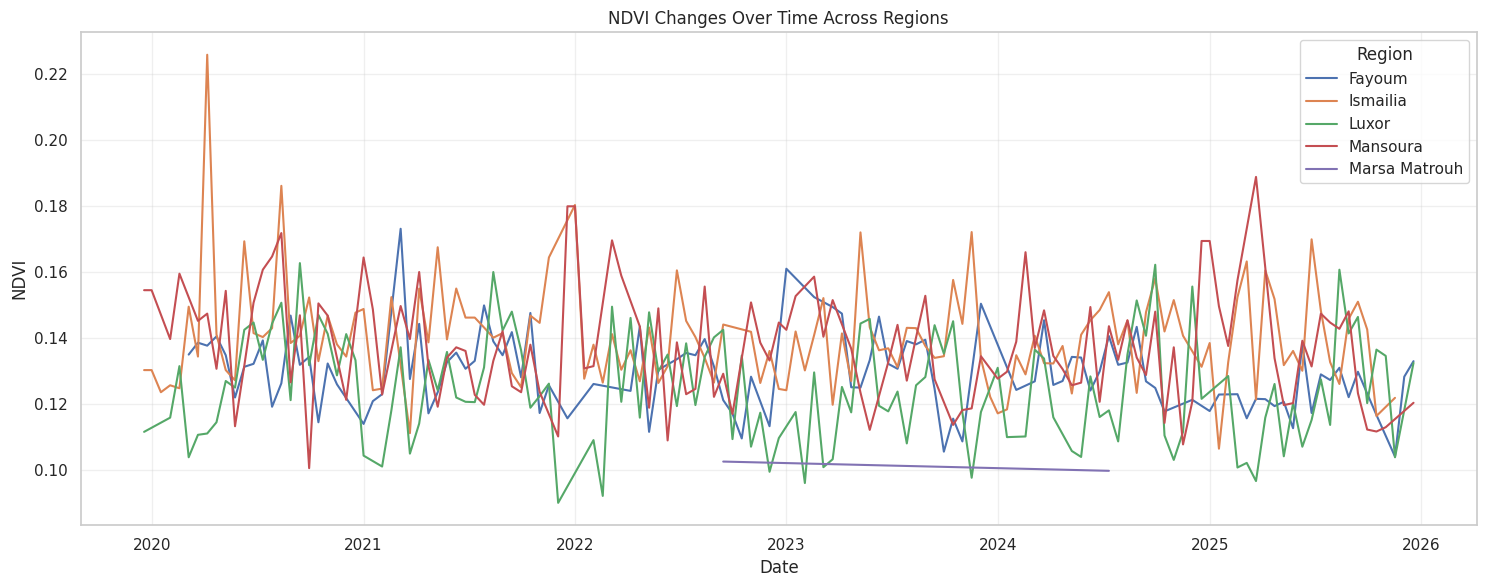

In [34]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=modis_eda[modis_eda["Is_Good"]],
    x="Date",
    y="NDVI",
    hue="Region"
)

plt.title("NDVI Changes Over Time Across Regions")
plt.xlabel("Date")
plt.ylabel("NDVI")
plt.legend(title="Region")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

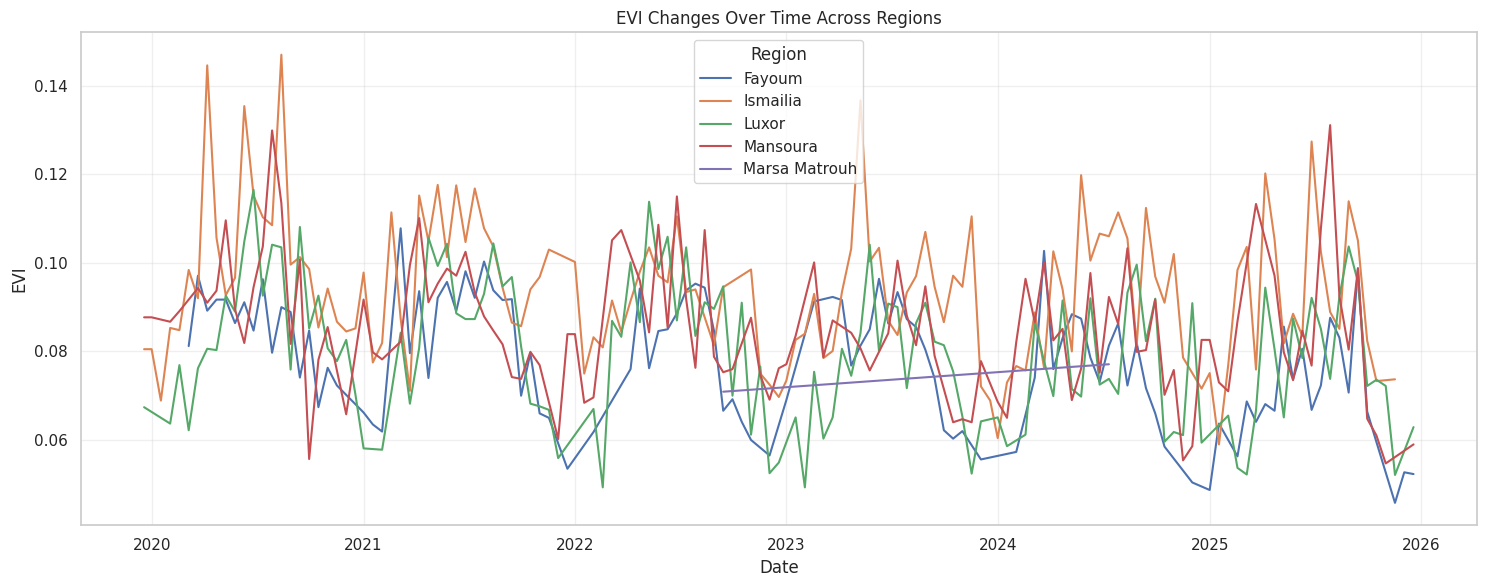

In [35]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=modis_eda[modis_eda["Is_Good"]],
    x="Date",
    y="EVI",
    hue="Region"
)

plt.title("EVI Changes Over Time Across Regions")
plt.xlabel("Date")
plt.ylabel("EVI")
plt.legend(title="Region")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

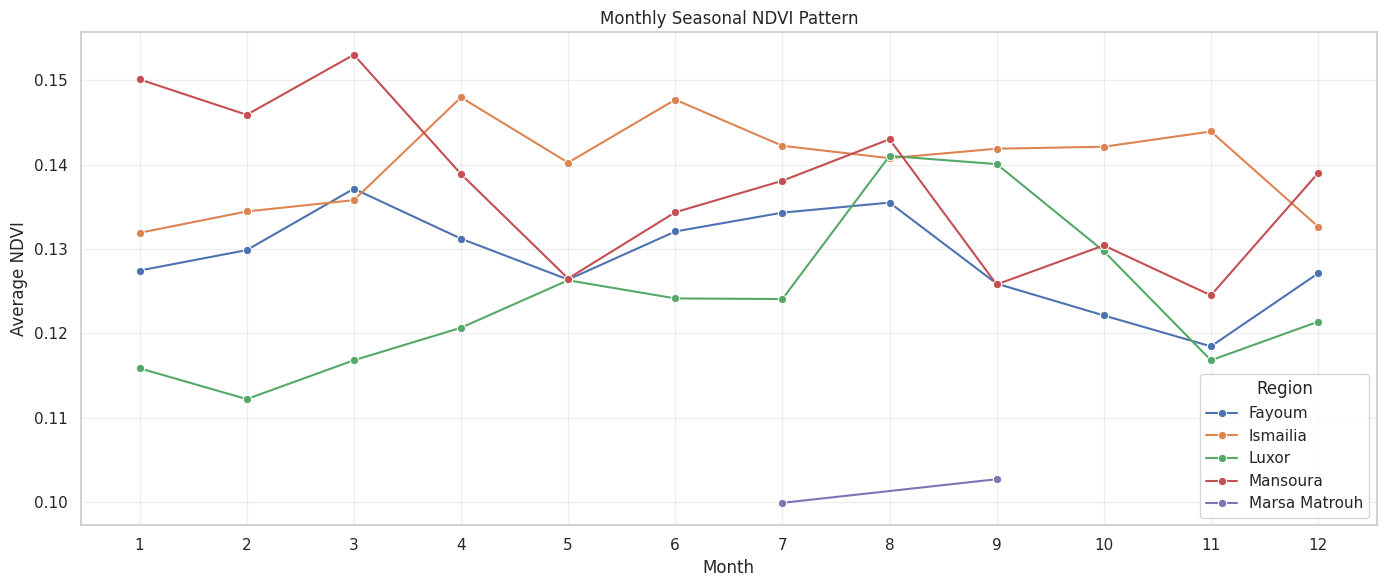

In [36]:
monthly_vegetation = (
    modis_eda[modis_eda["Is_Good"]]
    .groupby(["Region", "Month"])[["NDVI", "EVI"]]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_vegetation,
    x="Month",
    y="NDVI",
    hue="Region",
    marker="o"
)

plt.title("Monthly Seasonal NDVI Pattern")
plt.xlabel("Month")
plt.ylabel("Average NDVI")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
outlier_data = modis_eda[
    modis_eda["Is_Good"]
].copy()

def detect_outliers(group, column):

    Q1 = group[column].quantile(0.25)
    Q3 = group[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    return (
        (group[column] < lower_bound) |
        (group[column] > upper_bound)
    )

outlier_data["NDVI_Outlier"] = (
    outlier_data.groupby("Region", group_keys=False)
    .apply(lambda g: detect_outliers(g, "NDVI"))
    .reset_index(level=0, drop=True)
)

outlier_data["EVI_Outlier"] = (
    outlier_data.groupby("Region", group_keys=False)
    .apply(lambda g: detect_outliers(g, "EVI"))
    .reset_index(level=0, drop=True)
)

print("NDVI Outliers:", outlier_data["NDVI_Outlier"].sum())
print("EVI Outliers:", outlier_data["EVI_Outlier"].sum())

display(
    outlier_data[
        outlier_data["NDVI_Outlier"] | outlier_data["EVI_Outlier"]
    ][["Region", "Date", "NDVI", "EVI",
       "NDVI_Outlier", "EVI_Outlier"]]
)

NDVI Outliers: 7
EVI Outliers: 4


/tmp/ipykernel_50/193111389.py:22: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: detect_outliers(g, "NDVI"))
/tmp/ipykernel_50/193111389.py:28: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: detect_outliers(g, "EVI"))


,Region,Date,NDVI,EVI,NDVI_Outlier,EVI_Outlier
20,Fayoum,2020-10-31,0.1324,0.0763,True,False
54,Fayoum,2022-04-23,0.1436,0.0942,True,False
117,Fayoum,2025-01-17,0.1230,0.0637,True,True
125,Fayoum,2025-05-25,0.1128,0.0737,True,True
155,Ismailia,2020-08-28,0.1386,0.0996,True,False
196,Ismailia,2022-06-10,0.1316,0.0956,True,False
380,Luxor,2024-05-24,0.1041,0.0698,False,True
474,Mansoura,2022-06-10,0.1091,0.0854,True,False
481,Mansoura,2022-09-30,0.1171,0.0760,False,True


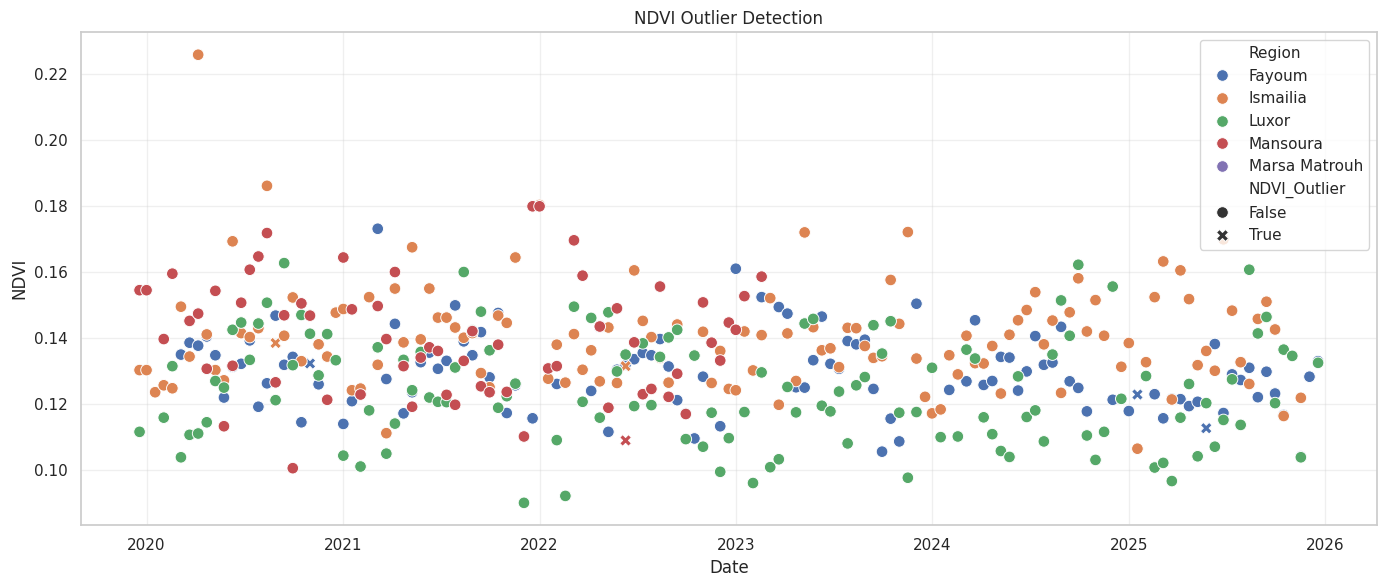

In [38]:
plt.figure(figsize=(14, 6))

sns.scatterplot(
    data=outlier_data,
    x="Date",
    y="NDVI",
    hue="Region",
    style="NDVI_Outlier",
    s=70
)

plt.title("NDVI Outlier Detection")
plt.xlabel("Date")
plt.ylabel("NDVI")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
# Keep only Good quality observations
modis_clean = modis_eda[
    modis_eda["Is_Good"] == True
].copy()

# Remove missing values in the main vegetation indicators
modis_clean = modis_clean.dropna(
    subset=["NDVI", "EVI", "Date", "Region"]
)

# Sort data
modis_clean = modis_clean.sort_values(
    ["Region", "Date"]
).reset_index(drop=True)

print("Original Records:", len(modis_eda))
print("Clean Records:", len(modis_clean))
print("Removed Records:", len(modis_eda) - len(modis_clean))

print("\nMissing Values:")
print(modis_clean[["NDVI", "EVI"]].isnull().sum())

display(modis_clean.head())

Original Records: 695
Clean Records: 491
Removed Records: 204

Missing Values:
NDVI    0
EVI     0
dtype: int64


,Region,ID,Latitude,Longitude,Date,MODIS_Tile,MOD13Q1_061_Line_Y_250m,MOD13Q1_061_Sample_X_250m,EVI,NDVI,...,MOD13Q1_061__250m_16_days_VI_Quality_Possible_shadow_Description,MOD13Q1_061__250m_16_days_pixel_reliability_bitmask,MOD13Q1_061__250m_16_days_pixel_reliability_MODLAND,Reliability_Description,Is_Good,Is_Marginal,Is_Cloudy,Year,Month,Season
0,Fayoum,Fayoum,29.31,30.84,2020-03-05,h20v06,331.0,3308.0,0.0812,0.1351,...,No,0b00000000000000000000000000000000,0b00000000000000000000000000000000,"Good data, use with confidence",True,False,False,2020,3,2
1,Fayoum,Fayoum,29.31,30.84,2020-03-21,h20v06,331.0,3308.0,0.0971,0.1387,...,No,0b00000000000000000000000000000000,0b00000000000000000000000000000000,"Good data, use with confidence",True,False,False,2020,3,2
2,Fayoum,Fayoum,29.31,30.84,2020-04-06,h20v06,331.0,3308.0,0.0892,0.1378,...,No,0b00000000000000000000000000000000,0b00000000000000000000000000000000,"Good data, use with confidence",True,False,False,2020,4,2
3,Fayoum,Fayoum,29.31,30.84,2020-04-22,h20v06,331.0,3308.0,0.0917,0.1406,...,No,0b00000000000000000000000000000000,0b00000000000000000000000000000000,"Good data, use with confidence",True,False,False,2020,4,2
4,Fayoum,Fayoum,29.31,30.84,2020-05-08,h20v06,331.0,3308.0,0.0917,0.1349,...,No,0b00000000000000000000000000000000,0b00000000000000000000000000000000,"Good data, use with confidence",True,False,False,2020,5,2


In [40]:
print("Clean Dataset Shape:", modis_clean.shape)

print("\nRecords Per Region:")
display(modis_clean.groupby("Region").size())

print("\nNDVI Statistics:")
display(modis_clean.groupby("Region")["NDVI"].describe())

print("\nEVI Statistics:")
display(modis_clean.groupby("Region")["EVI"].describe())

Clean Dataset Shape: (491, 40)

Records Per Region:


Region
Fayoum           110
Ismailia         131
Luxor            127
Mansoura         121
Marsa Matrouh      2
dtype: int64


NDVI Statistics:


,count,mean,std,min,25%,50%,75%,max
Region,,,,,,,,
Fayoum,110.0,0.129752,0.011539,0.1042,0.122125,0.1295,0.135475,0.1732
Ismailia,131.0,0.140184,0.015561,0.1066,0.130400,0.1388,0.146300,0.2259
Luxor,127.0,0.124672,0.016365,0.0902,0.111450,0.1225,0.136150,0.1628
Mansoura,121.0,0.137777,0.017071,0.1007,0.123800,0.1371,0.148800,0.1889
Marsa Matrouh,2.0,0.101300,0.001980,0.0999,0.100600,0.1013,0.102000,0.1027



EVI Statistics:


,count,mean,std,min,25%,50%,75%,max
Region,,,,,,,,
Fayoum,110.0,0.077916,0.013931,0.0458,0.06660,0.07965,0.089175,0.1078
Ismailia,131.0,0.093812,0.016029,0.0590,0.08215,0.09400,0.103450,0.1470
Luxor,127.0,0.079695,0.015560,0.0493,0.06720,0.08060,0.091300,0.1165
Mansoura,121.0,0.085077,0.014700,0.0547,0.07610,0.08390,0.094300,0.1311
Marsa Matrouh,2.0,0.074000,0.004384,0.0709,0.07245,0.07400,0.075550,0.0771


In [41]:
features_df = modis_clean.copy()

# Previous observations
features_df["Previous_NDVI"] = (
    features_df.groupby("Region")["NDVI"].shift(1)
)

features_df["Previous_EVI"] = (
    features_df.groupby("Region")["EVI"].shift(1)
)

features_df["Previous_Date"] = (
    features_df.groupby("Region")["Date"].shift(1)
)

# Time difference in days
features_df["Days_Difference"] = (
    features_df["Date"] - features_df["Previous_Date"]
).dt.days

# NDVI change
features_df["NDVI_Change"] = (
    features_df["NDVI"] - features_df["Previous_NDVI"]
)

# NDVI change rate per day
features_df["NDVI_Change_Rate"] = (
    features_df["NDVI_Change"] /
    features_df["Days_Difference"]
)

# EVI change
features_df["EVI_Change"] = (
    features_df["EVI"] - features_df["Previous_EVI"]
)

# Rolling EVI trend (3 observations)
features_df["EVI_Trend"] = (
    features_df.groupby("Region")["EVI"]
    .transform(lambda x: x.rolling(3, min_periods=1).mean())
)

display(
    features_df[
        ["Region", "Date", "NDVI", "NDVI_Change",
         "NDVI_Change_Rate", "EVI", "EVI_Trend"]
    ].head(15)
)

,Region,Date,NDVI,NDVI_Change,NDVI_Change_Rate,EVI,EVI_Trend
0,Fayoum,2020-03-05,0.1351,NaN,NaN,0.0812,0.081200
1,Fayoum,2020-03-21,0.1387,0.0036,0.000225,0.0971,0.089150
2,Fayoum,2020-04-06,0.1378,-0.0009,-0.000056,0.0892,0.089167
3,Fayoum,2020-04-22,0.1406,0.0028,0.000175,0.0917,0.092667
4,Fayoum,2020-05-08,0.1349,-0.0057,-0.000356,0.0917,0.090867
5,Fayoum,2020-05-24,0.1221,-0.0128,-0.000800,0.0864,0.089933
6,Fayoum,2020-06-09,0.1314,0.0093,0.000581,0.0911,0.089733
7,Fayoum,2020-06-25,0.1323,0.0009,0.000056,0.0847,0.087400
8,Fayoum,2020-07-11,0.1394,0.0071,0.000444,0.0963,0.090700
9,Fayoum,2020-07-27,0.1193,-0.0201,-0.001256,0.0797,0.086900


In [42]:
features_df["Month_Sin"] = np.sin(
    2 * np.pi * features_df["Month"] / 12
)

features_df["Month_Cos"] = np.cos(
    2 * np.pi * features_df["Month"] / 12
)

display(
    features_df[
        ["Region", "Date", "Month", "Month_Sin", "Month_Cos"]
    ].head()
)

,Region,Date,Month,Month_Sin,Month_Cos
0,Fayoum,2020-03-05,3,1.000000,6.123234e-17
1,Fayoum,2020-03-21,3,1.000000,6.123234e-17
2,Fayoum,2020-04-06,4,0.866025,-5.000000e-01
3,Fayoum,2020-04-22,4,0.866025,-5.000000e-01
4,Fayoum,2020-05-08,5,0.500000,-8.660254e-01


In [43]:
# Average NDVI for each region and month
seasonal_baseline = (
    features_df.groupby(["Region", "Month"])["NDVI"]
    .mean()
    .rename("NDVI_Seasonal_Baseline")
    .reset_index()
)

features_df = features_df.merge(
    seasonal_baseline,
    on=["Region", "Month"],
    how="left"
)

# Vegetation anomaly
features_df["Vegetation_Anomaly"] = (
    features_df["NDVI"] -
    features_df["NDVI_Seasonal_Baseline"]
)

display(
    features_df[
        ["Region", "Date", "NDVI",
         "NDVI_Seasonal_Baseline", "Vegetation_Anomaly"]
    ].head(15)
)

,Region,Date,NDVI,NDVI_Seasonal_Baseline,Vegetation_Anomaly
0,Fayoum,2020-03-05,0.1351,0.137133,-0.002033
1,Fayoum,2020-03-21,0.1387,0.137133,0.001567
2,Fayoum,2020-04-06,0.1378,0.131217,0.006583
3,Fayoum,2020-04-22,0.1406,0.131217,0.009383
4,Fayoum,2020-05-08,0.1349,0.126367,0.008533
5,Fayoum,2020-05-24,0.1221,0.126367,-0.004267
6,Fayoum,2020-06-09,0.1314,0.132067,-0.000667
7,Fayoum,2020-06-25,0.1323,0.132067,0.000233
8,Fayoum,2020-07-11,0.1394,0.134300,0.005100
9,Fayoum,2020-07-27,0.1193,0.134300,-0.015000


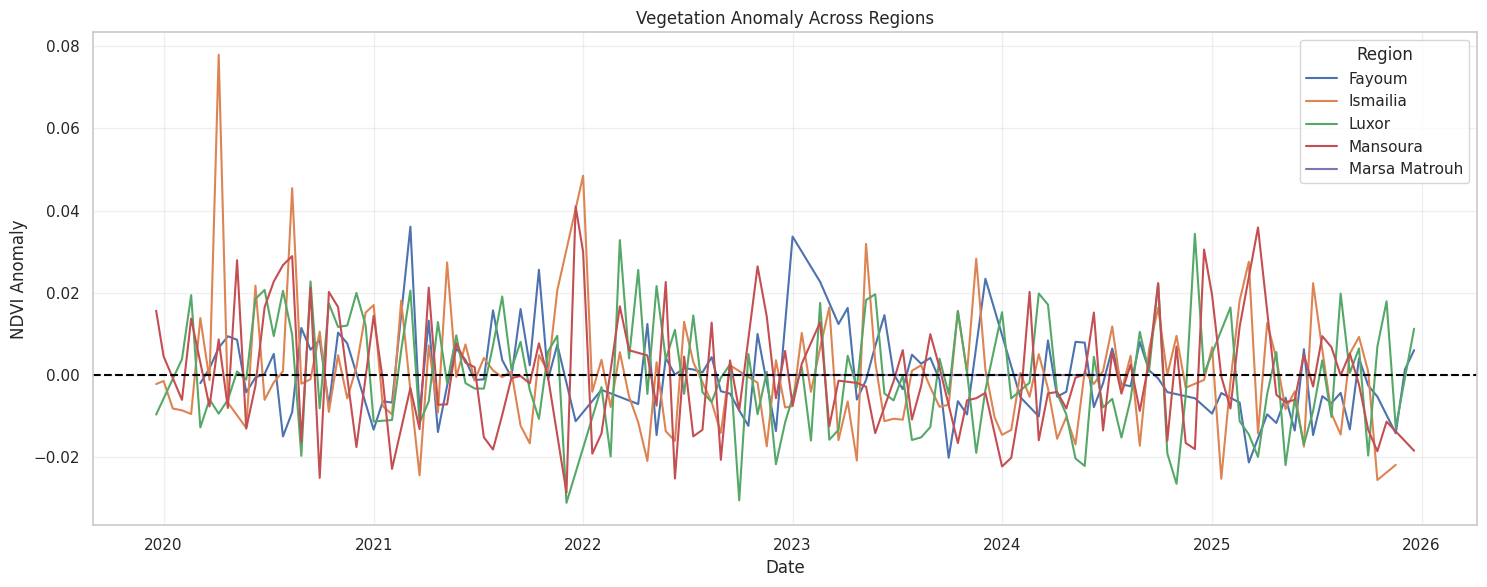

In [44]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=features_df,
    x="Date",
    y="Vegetation_Anomaly",
    hue="Region"
)

plt.axhline(0, linestyle="--", color="black")

plt.title("Vegetation Anomaly Across Regions")
plt.xlabel("Date")
plt.ylabel("NDVI Anomaly")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# MODIS Vegetation Dataset — Documentation

## 1. Dataset Overview

This dataset was collected from NASA's **MODIS (Moderate Resolution Imaging Spectroradiometer)** satellite product.

- **Product:** MOD13Q1.061
- **Spatial Resolution:** 250 meters
- **Temporal Resolution:** 16-day composites
- **Study Period:** 2020–2025
- **Number of Regions:** 5
- **Total Records:** 695

The dataset provides vegetation information for five selected regions in Egypt.

## 2. Study Regions

The selected regions are:

- Mansoura
- Fayoum
- Ismailia
- Luxor
- Marsa Matrouh

Each region is represented by its geographic coordinates (Latitude and Longitude).

## 3. Collected Data Layers

The following MODIS layers were collected:

| Layer | Description |
|---|---|
| NDVI | Normalized Difference Vegetation Index |
| EVI | Enhanced Vegetation Index |
| VI Quality | Quality information associated with vegetation indices |
| Pixel Reliability | Pixel-level reliability classification |

### NDVI
NDVI measures vegetation greenness and helps estimate vegetation density and health.

### EVI
EVI is another vegetation index designed to improve vegetation monitoring, particularly in areas with dense vegetation.

### Pixel Reliability
This layer indicates the reliability of each vegetation observation.

The observations are classified into:
- **Good:** Reliable observations.
- **Marginal:** Observations with some quality limitations.
- **Cloudy:** Observations affected by cloud conditions.

## 4. Initial Dataset Analysis

The downloaded dataset contains:

- 695 records
- 5 regions
- 139 observations per region
- Date range: December 2019 – December 2025

Initial data quality checks showed:
- No missing values in the collected dataset.
- No duplicate Region-Date records.
- Different reliability levels across the selected regions.

## 5. Data Quality Results

The pixel reliability distribution is:

| Reliability | Number of Records |
|---|---:|
| Good | 491 |
| Marginal | 149 |
| Cloudy | 55 |

Observations classified as **Good** were selected for the main cleaned dataset.

**Important observation:** Marsa Matrouh has only 2 Good observations out of 139 records. Therefore, its vegetation trends require special attention and should not be interpreted as statistically reliable based on the current cleaned data.

## 6. Preprocessing and Feature Engineering

The MODIS data processing includes:

1. Date conversion and extraction of Year and Month.
2. Checking pixel reliability.
3. Separating reliable observations from lower-quality observations.
4. Creating a cleaned dataset using Good observations.
5. Sorting records by region and date.
6. Detecting potential outliers using the IQR method.
7. Creating temporal and seasonal features.

### Engineered Features

| Feature | Description |
|---|---|
| NDVI_Change | Difference between current and previous NDVI |
| NDVI_Change_Rate | NDVI change relative to the time difference |
| EVI_Change | Difference between current and previous EVI |
| EVI_Trend | Rolling average of EVI |
| Month_Sin / Month_Cos | Cyclical representation of the month |
| Vegetation_Anomaly | Difference between observed NDVI and the regional monthly baseline |

## 7. Final Processed Dataset

After filtering for Good-quality observations, the cleaned dataset contains:

**491 records and 40 columns.**

The original dataset and quality information should also be retained for future analysis and integration.

## 8. Important Notes for Data Integration

- MODIS observations represent 16-day composites.
- Other datasets may have different temporal and spatial resolutions.
- Temporal and spatial alignment will be required before combining datasets.
- Quality flags should be preserved to support reliable analysis.
- Regions with insufficient Good observations should be treated carefully.

